Week 2 libraries loaded. Ready to go!
Target variable: close
My X columns: ['open', 'high', 'low']

--- Ridge Regression Results ---
Train R-squared: 0.9990
Test R-squared:  0.9990
Test RMSE error: 0.0706

--- Lasso Regression Results ---
Train R-squared: 0.9964
Test R-squared:  0.9964
Test RMSE error: 0.1335

--- Elastic Net Results ---
Train R-squared: 0.9961
Test R-squared:  0.9961
Test RMSE error: 0.1387

Coefficient Comparison Table:
  Feature     Ridge     Lasso  ElasticNet
0    open -1.002044  0.000000    0.672038
1    high  1.535175  1.080532    0.746021
2     low  1.718873  1.072218    0.747511


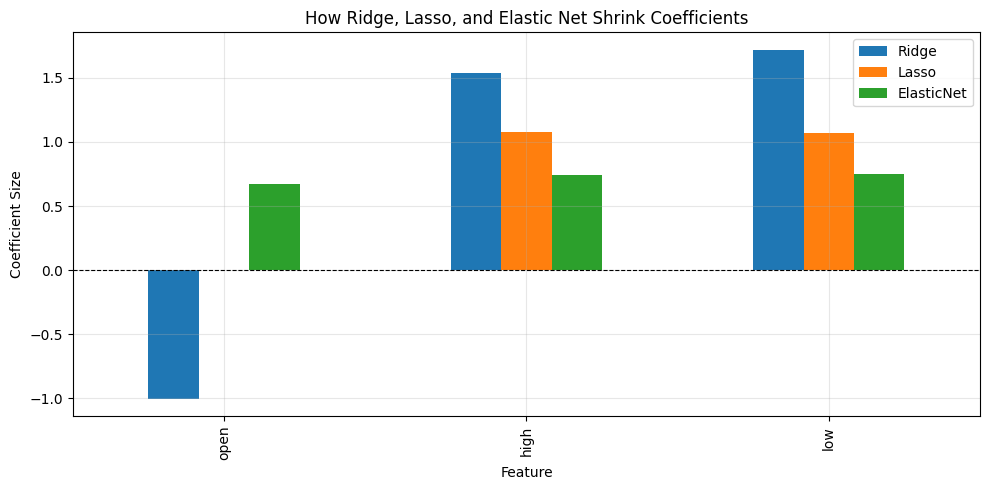

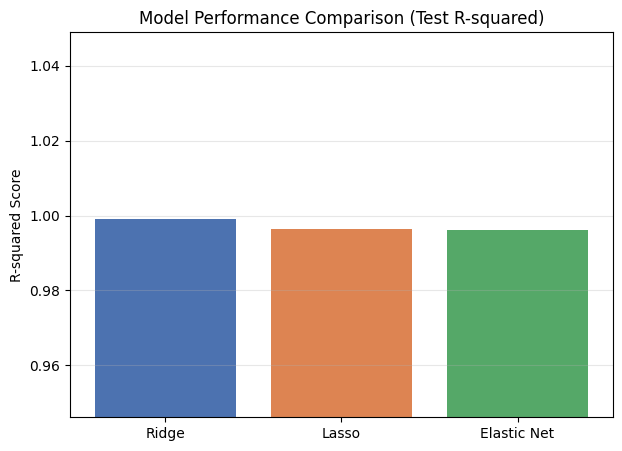

In [1]:
# Step 1: Getting the libraries ready for Week 2 (Regularization)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, r2_score

print("Week 2 libraries loaded. Ready to go!")

# Step 2: Load the gas dataset from the class GitHub
link_gas = "https://raw.githubusercontent.com/JSFranco-DS/DX699S/main/Natural_Gas_data.csv"
df_gas = pd.read_csv(link_gas)

# Set our target (what we want to predict) and our features
y_name = 'close'

# Grab only the number columns so we don't get errors
num_cols = df_gas.select_dtypes(include=[np.number]).columns.tolist()

# remove the target from our feature list so we don't accidentally cheat
if y_name in num_cols:
    num_cols.remove(y_name)

# drop any missing values (NaNs) so the models don't crash
clean_df = df_gas[[y_name] + num_cols].dropna()

# Picking the first 3 number columns for X to keep it simple for now
X = clean_df[num_cols[:3]]
y = clean_df[y_name]

print("Target variable:", y_name)
print("My X columns:", X.columns.tolist())

# Step 3: Split the data into Train and Test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale the numbers! This is super important for Ridge and Lasso so the penalties are fair.
my_scaler = StandardScaler()
X_train_scaled = my_scaler.fit_transform(X_train)
X_test_scaled = my_scaler.transform(X_test)

# Step 4: Try Ridge Regression (L2 Penalty)
# Ridge shrinks the coefficients to handle multicollinearity without dropping them completely.
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_scaled, y_train)

# make guesses for train and test
ridge_train_guess = ridge_model.predict(X_train_scaled)
ridge_test_guess = ridge_model.predict(X_test_scaled)

print("\n--- Ridge Regression Results ---")
print(f"Train R-squared: {r2_score(y_train, ridge_train_guess):.4f}")
print(f"Test R-squared:  {r2_score(y_test, ridge_test_guess):.4f}")
print(f"Test RMSE error: {np.sqrt(mean_squared_error(y_test, ridge_test_guess)):.4f}")

# Step 5: Try Lasso Regression (L1 Penalty)
# Lasso is cool because it acts like an automatic feature selector and drops useless variables to exactly zero.
lasso_model = Lasso(alpha=0.1)
lasso_model.fit(X_train_scaled, y_train)

lasso_train_guess = lasso_model.predict(X_train_scaled)
lasso_test_guess = lasso_model.predict(X_test_scaled)

print("\n--- Lasso Regression Results ---")
print(f"Train R-squared: {r2_score(y_train, lasso_train_guess):.4f}")
print(f"Test R-squared:  {r2_score(y_test, lasso_test_guess):.4f}")
print(f"Test RMSE error: {np.sqrt(mean_squared_error(y_test, lasso_test_guess)):.4f}")

# Step 6: Try Elastic Net (Mix of Ridge and Lasso)
# This one takes the best of both penalties. l1_ratio=0.5 means a 50/50 mix.
enet_model = ElasticNet(alpha=0.1, l1_ratio=0.5)
enet_model.fit(X_train_scaled, y_train)

enet_train_guess = enet_model.predict(X_train_scaled)
enet_test_guess = enet_model.predict(X_test_scaled)

print("\n--- Elastic Net Results ---")
print(f"Train R-squared: {r2_score(y_train, enet_train_guess):.4f}")
print(f"Test R-squared:  {r2_score(y_test, enet_test_guess):.4f}")
print(f"Test RMSE error: {np.sqrt(mean_squared_error(y_test, enet_test_guess)):.4f}")

# Step 7: Create a graph for the milestone report appendix
# Put all the coefficients in a table so we can see how Lasso drives some down to zero
coef_table = pd.DataFrame({
    'Feature': X.columns,
    'Ridge': ridge_model.coef_,
    'Lasso': lasso_model.coef_,
    'ElasticNet': enet_model.coef_
})

print("\nCoefficient Comparison Table:")
print(coef_table)

# Plot the bar chart to show how the models shrink the coefficients differently
coef_table.set_index('Feature').plot(kind='bar', figsize=(10, 5))
plt.title("How Ridge, Lasso, and Elastic Net Shrink Coefficients")
plt.ylabel("Coefficient Size")
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Extra coding for Milestone One report for Model Performance Comparison
r2_scores = [
    r2_score(y_test, ridge_test_guess),
    r2_score(y_test, lasso_test_guess),
    r2_score(y_test, enet_test_guess)
]
models = ['Ridge', 'Lasso', 'Elastic Net']

plt.figure(figsize=(7, 5))
plt.bar(models, r2_scores, color=['#4C72B0', '#DD8452', '#55A868'])
plt.title('Model Performance Comparison (Test R-squared)')
plt.ylabel('R-squared Score')
plt.ylim(min(r2_scores) - 0.05, max(r2_scores) + 0.05) # Zooms in to show the difference
plt.grid(axis='y', alpha=0.3)
plt.show()